Billy York


5/14/2026

# Collaborative Filtering with kNN

## Analysis

### Dataset Splits

> For each of the datasets, approximately 80% of the users are in the training set and the remaining 20% are in both the seen and unseen testing sets. Similarly, 80% of the ratings are in the training set, but about 14% of the ratings are in the seen set with the remaining 6% of ratings being in the unseen testing sets. 

#### Number of Users

| Partition | MovieLens | Netflix Prize | Yahoo! R2 Songs | BoardGameGeek |
| - | - | - | - | - |
| Total | 162541 | 473816 | 200000 | 332079 |
| Training | 130032 | 379052 | 160000 | 265663 |
| Query | 32509 | 94764 | 40000 | 66416 |
| Test | 32509 | 94764 | 40000 | 66416 |

#### Number of Ratings

| Partition | MovieLens | Netflix Prize | Yahoo! R2 Songs | BoardGameGeek |
| - | - | - | - | - |
| Total | 24890583 | 51027153 | 76344627 | 18862919 |
| Training | 19927303 | 40811707 | 61162037 | 15046783 |
| Query | 3474296 | 7150812 | 10627813 | 2671295 |
| Test | 1488984 | 3064634 | 4554777 | 1144841 |

### Choosing k

> k=500 produced the best model for each dataset, all improving over non-personalized recommendations. With the exception of BoardGameGeek's dataset, all improved signifcantly as well. This wasn't too surprising, though I would expect there to be a point where more neighbors actively hurts the model since k would eventually include the entire dataset which would be the same as non-personalized recommendations. I wonder if weighting the averages proprotionally to their normalized closeness metric could improve accuracy. 

#### R2 Values per k Value

| k | MovieLens | Netflix Prize | Yahoo! R2 Songs | BoardGameGeek |
| - | - | - | - | - |
| 5 | 0.14942083809141932 | 0.11761670877210213 | 0.08944845695550227 | 0.16647374063089776 |
| 25 | 0.19573076131926403 | 0.16564594953318715 | 0.13497192540128103 | 0.20060137268011743 |
| 50 | 0.21085131034930488 | 0.18352119978030748 | 0.15753527685903118 | 0.21768923836819856 |
| 100 | 0.22367766439928108 | 0.19787464423269144 | 0.17800696133522587 | 0.23486229579143142 |
| 150 | 0.22971036695722072 | 0.2050785501100337 | 0.18904838300461227 | 0.244396405042503 | 
| 200 | 0.23332176869463 | 0.20944404688347693 | 0.19672314526439233 | 0.2508979763628055 |
| 250 | 0.23578125151151302 | 0.21216979266859393 | 0.2026003859242363 | 0.2556668288928002 |
| 300 | 0.2376110982783566 | 0.21415764244961824 | 0.20712703774140823 | 0.2594815418929492 |
| 350 | 0.238589000552964 | 0.215778709974334 | 0.21091457790307572 | 0.2625001050195095 |
| 400 | 0.23950493131933526 | 0.21708428071494112 | 0.2141638676228379 | 0.2646691960327889 |
| 450 | 0.23999315996527806 | 0.2181814376306204 | 0.2164095964728002 | 0.266969743459352 |
| 500 | **0.24028419710233104** | **0.21889972279961534** | **0.21828409756369396** | **0.2688684976673277** |


### How R² Scales with k

> All datasets' R2 values scaled logarithmically with k. The rate of increase, or the point of diminishing returns all seemed to occur around k=100 where the graph begins to plateau and level off. 

#### R2 Value vs k Value

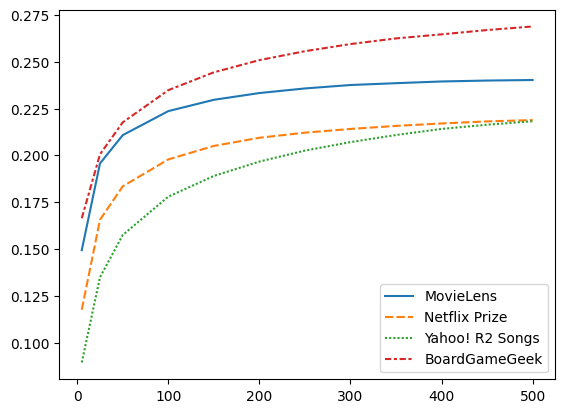

### Compared with Non-Personalized Recommendations

> kNN greatly improved the R2 value for all datasets except for BoardGameGeek where it still improved, just to a lesser degree. 

#### MovieLens Predicted Ratings Distribution

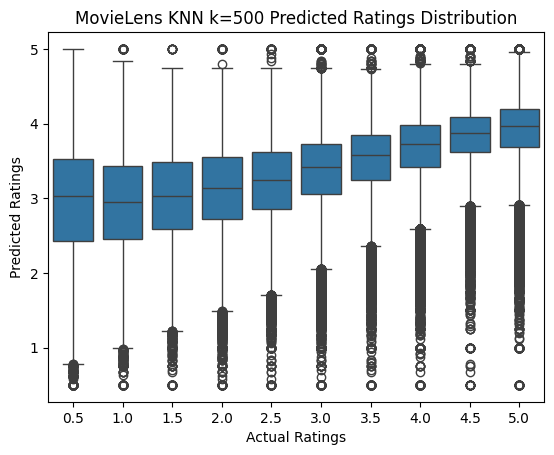


#### Netflix Prize Predicted Ratings Distribution

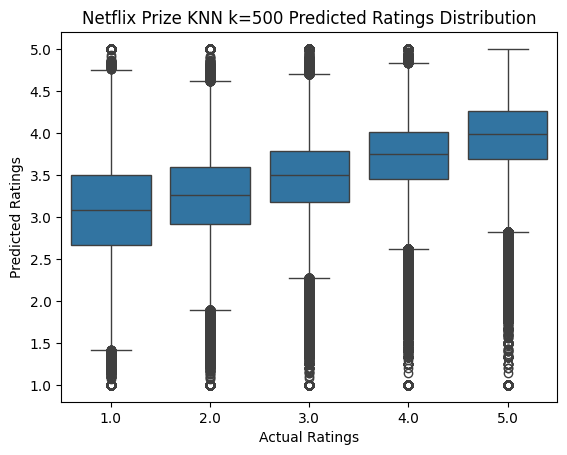


#### Yahoo! R2 Songs Predicted Ratings Distribution

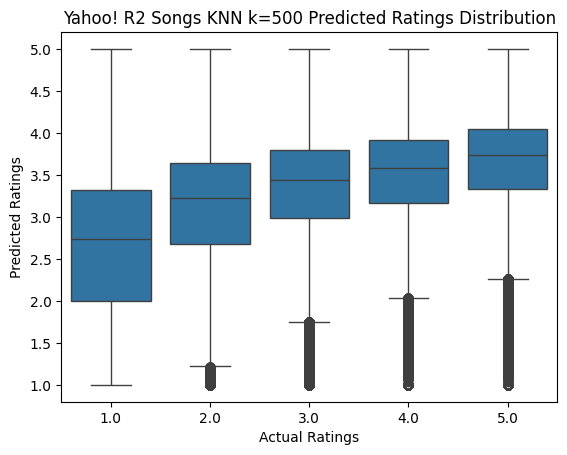

### Predictions per User

> There are about 5 times less ratings per user than non-personalized algorithms. 

### MovieLens Predicted Ratings Per User Distribution

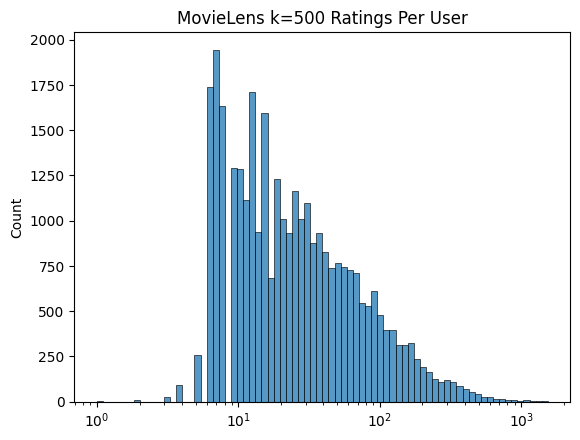

### Netflxi PRize Predicted Ratings Per User Distribution

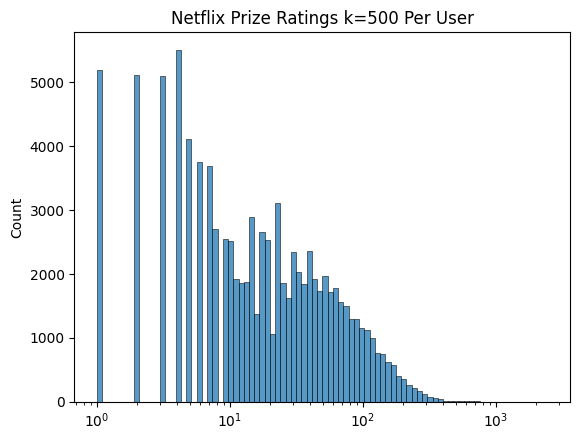

### Yahoo! R2 Songs Predicted Ratings Per User Distribution

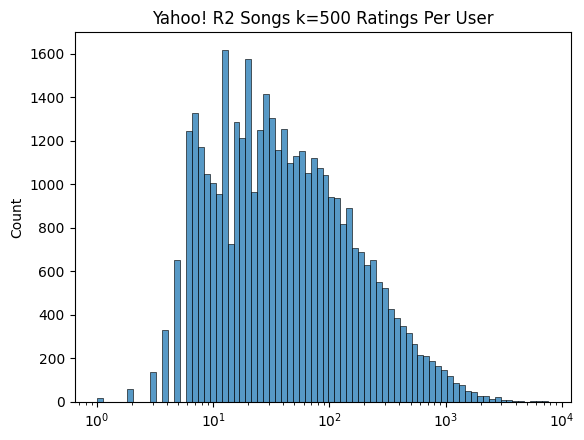

### BoardGameGeek Predicted Ratings Per User Distribution

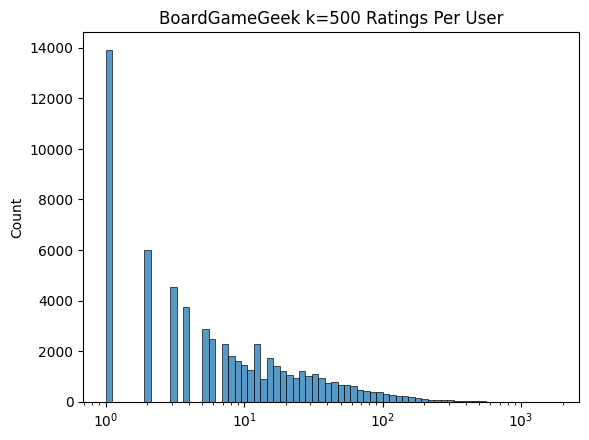

### Strengths and Weaknesses

> kNN provides better R2 scores than non-personalized algorithms at the cost of significantly more compute resources. It also requires a more complex implementation than non-personalized recommendations do. 

## Appendix: Polars Memory Management

### Introduction: What's the Problem?
This project took several attempts to complete due to the large size of the datasets. Specifically joining the neighbors found from the query set with the training set. These DataFrames could easily get to be over 100GB before either the python kernel crashed or my entire computer crashed (thankfully, I never managed to crash the school's supercomputer in spite of getting very close to a single node's memory limit, approximately ~360GB of memory used before searching for another solution). 

Part of this was poor memory management in the implementation, however there is a known issue with Polars' memory allocation. It uses a tool called jemalloc which has it's own set of issues around the activeness of its development, but they are not relevant to this discussion. Polars specifically sets jemalloc's "dirty decay" and "muzzy decay" to -1, which in essence means it doesn't release the memory back to the operating system when it's done using it. Polars does this so it only has to allocate memory once and any likely similarly sized datasets will reuse that memory. The issue is it _won't_ reuse memory if it thinks it's fragmented and _won't_ take time to unfragment it, instead opting to simply allocate more memory. This behavior can be seen in htop during a long run of using Polars.

### Solutions
Here are a few tricks I found while scouring the internet for fixes to this and general better memory management with Polars:

1. Set the environment variable `_RJEM_MALLOC_CONF` to `abort_conf:true,dirty_decay_ms:0,muzzy_decay_ms:0`. This will enable jemalloc to return memory to the operating system as soon as its available. 

2. Use Polars only in subprocesses. By putting Polars into a subprocess, when it finishes, the memory is returned to the operating system.

3. Use Polars' LazyFrames and Streaming Engine. This seems to be under active development as there is not full parity with DataFrames yet. Essentially, Polars will put off computation until it is specifically asked to, then will load only what is necessary into memory. I added in-between steps of using `scan_ipc() and sink_ipc()` to use the disk as an intermediary.

4. Do everything for one dataset before moving to the next. I first did all k=5, then all k=25, etc. This meant my computer was attempting to keep every DataFrame in memory at the same time. Switching to this and attempting to `del` the DataFrames after they were no longer needed is what lead to discovering the memory leak in Polars. 

5. Batch Process. This took 3 attempts for me to figure out how to do properly. My issue was simply batching on the wrong column, `training_user_id` instead of `query_user_id`. This ended up being the only needed solution in the end, but I figured it would be worth sharing everything else I learned about Polars along the way.

In [1]:
import os
os.environ['POLARS_MAX_THREADS'] = '10'
os.environ['POLARS_ENGINE_AFFINITY'] = 'streaming'
os.environ['_RJEM_MALLOC_CONF']='abort_conf:true,dirty_decay_ms:0,muzzy_decay_ms:0'

In [2]:
import numpy as np
import polars as pl
from scipy import sparse
from scipy import stats

from sklearn import model_selection
from sklearn import neighbors

import seaborn as sns
from IPython.display import display, Markdown

In [3]:
def df_to_sparse(df, n_items):
    uniq_user_ids = set(df['user_id'].unique())
    user_id_to_indices = { orig_user_id : new_user_id for new_user_id, orig_user_id in enumerate(uniq_user_ids) }
    new_user_ids = df['user_id'].replace_strict(user_id_to_indices).to_numpy()
    indices_to_user_ids = { new_user_id : orig_user_id for orig_user_id, new_user_id in user_id_to_indices.items() }

    training_X = sparse.csr_matrix(
        (df['rating'].to_numpy(), (new_user_ids, df['item_id'].to_numpy())),
        shape=(len(uniq_user_ids), n_items))

    return training_X, indices_to_user_ids

In [4]:
class RatingsAverager:
    def __init__(self, training_df):
        self.training_df = training_df

    def predictRatings(self, neighbors_df, name, k):
        print('Joining With Training DF...')
        # joined_df = None
        # if not os.path.exists(f'{name}_joined_df_{k}.feather'):
        batches = []
        for i in range(neighbors_df['query_user_id'].max() // 1000):
            batch_df = neighbors_df.filter(pl.col('query_user_id').is_between(lower_bound=i*1000, upper_bound=(i+1)*1000))
            batch_df = batch_df.join(self.training_df, left_on = 'training_user_id', right_on = 'user_id').select(['query_user_id', 'item_id', 'rating']).group_by(['query_user_id', 'item_id']).agg(pl.col('rating').mean()).rename({ 'query_user_id' : 'user_id', 'rating' : 'pred_rating'})
            batches.append(batch_df)
        pred_df = pl.concat(batches)
        print(pred_df.head())
        return pred_df.lazy()
        # neighbors_df.join(self.training_df.lazy(), left_on = 'training_user_id', right_on = 'user_id')
        # .select(['query_user_id', 'item_id', 'rating'])
        # .group_by(['query_user_id', 'item_id']).mean()
        # .rename({ 'query_user_id' : 'user_id', 'rating' : 'pred_rating' })

        # return neighbors_df.join(self.training_df.lazy(), left_on = 'training_user_id', right_on = 'user_id').select(['query_user_id', 'item_id', 'rating']).group_by(['query_user_id', 'item_id']).mean().rename({ 'query_user_id' : 'user_id', 'rating' : 'pred_rating' })
        # joined_df = pl.scan_ipc(f'{name}_joined_df_{k}.feather', memory_map=False)
        # print('Averaging Ratings...')
        # pred_df = None
        # if not os.path.exists(f'{name}_pred_df_{k}.feather'):
        #     joined_df.group_by(['query_user_id', 'item_id']).mean().sink_ipc(f'{name}_pred_df_{k}.feather', engine='streaming')
        # pred_df = pl.scan_ipc(f'{name}_pred_df_{k}.feather')
        # return pred_df.rename({ 'query_user_id' : 'user_id', 'rating' : 'pred_rating' })


In [5]:
class KNN:
    def __init__(self, reference_df, query_df):
        self.query_df = query_df
        self.reference_df = reference_df
        self.ratings_averager = RatingsAverager(reference_df)

        ref_items = reference_df['item_id'].max() + 1
        query_items = query_df['item_id'].max() + 1
        self.n_items = max(ref_items, query_items)

        self.n_query_users = query_df['user_id'].n_unique()
        self.nn = None
        self.k = None

    def findNeighbors(self, k, n_jobs=None):
        self.k = k
        self.nn = neighbors.NearestNeighbors(n_neighbors=k, n_jobs=n_jobs, metric='cosine')
        reference_X, self.reference_indices_to_user_ids = df_to_sparse(self.reference_df, self.n_items)
        print('Fitting KNN to Training DF...')
        self.nn.fit(reference_X)

        query_X, self.query_indices_to_user_ids = df_to_sparse(self.query_df, self.n_items)
        print('Finding K Nearest Neighbors of Query DF...')
        self.neighbors_indices = self.nn.kneighbors(query_X, return_distance=False)

    def predictRatings(self, k, name):
        if self.nn is None:
            raise Exception('Need to run findNeighbors() first')

        if k > self.k:
            raise Exception('Number of neighbors used for predicting ratings must be <= number of neighbors found in search.')

        neighbors_df = None
        print('Converting Neighbor DF...')
        if not os.path.exists(f'{name}_neighbors_df_{k}.feather'):
            neighbors_indices = self.neighbors_indices[:, :k]
            neighbors_df = pl.LazyFrame({ 'neighbor_idx' : neighbors_indices.reshape(-1), 'query_idx' : np.arange(self.n_query_users).repeat(k) })
            if name == 'bg':
                nieghbor_map_df = pl.LazyFrame(data=np.array(list(self.reference_indices_to_user_ids.items())), schema={'neighbor_idx':pl.Int64, 'training_user_id':pl.String})
                query_map_df = pl.LazyFrame(data=np.array(list(self.query_indices_to_user_ids.items())), schema={'query_idx':pl.Int64, 'query_user_id':pl.String})
                neighbors_df = neighbors_df.join(nieghbor_map_df, on='neighbor_idx').drop('neighbor_idx')
                neighbors_df = neighbors_df.join(query_map_df, on='query_idx').drop('query_idx').select(['training_user_id', 'query_user_id'])#.sink_ipc(f'{name}_neighbors_df_{k}.feather')
            else:
                neighbors_df = neighbors_df.with_columns((pl.col('neighbor_idx').replace(self.reference_indices_to_user_ids).alias('training_user_id'), pl.col('query_idx').replace(self.query_indices_to_user_ids).alias('query_user_id'))).select(['training_user_id', 'query_user_id'])#.sink_ipc(f'{name}_neighbors_df_{k}.feather')
        # del neighbors_df
        # neighbors_df = pl.scan_ipc(f'{name}_neighbors_df_{k}.feather')
        neighbors_df = neighbors_df.collect(engine='streaming')
        return self.ratings_averager.predictRatings(neighbors_df, name, k)

In [6]:
def process(dataset, datafile, k):
    if os.path.exists(f'{dataset}_common_ratings_df_{k}.feather'):
        common_ratings_df = pl.read_ipc(f'{dataset}_common_ratings_df_{k}.feather')
        result = stats.pearsonr(common_ratings_df['pred_rating'].to_numpy(), common_ratings_df['rating'].to_numpy()).statistic ** 2
        del common_ratings_df

        print(f'{dataset.upper()} k={k} R2: {result}')
        return result
    
    ratings_df = pl.read_ipc(datafile, memory_map=False).fill_null('').filter(pl.col('user_id').is_duplicated())
    
    uniq_item_ids = set(ratings_df['item_id'].unique())
    item_id_map = { orig_item_id : new_item_id for new_item_id, orig_item_id in enumerate(uniq_item_ids) }
    
    ratings_df = ratings_df.with_columns(pl.col('rating').cast(pl.Float64), item_id = ratings_df['item_id'].replace(item_id_map))
    gss = model_selection.GroupShuffleSplit(n_splits=5, random_state=42)
    train_idx, test_idx = next(gss.split(ratings_df, None, ratings_df['user_id']))
    training_df = ratings_df[train_idx]
    leftover_df = ratings_df[test_idx]

    query_df, test_df = model_selection.train_test_split(leftover_df, train_size=0.7, stratify=leftover_df['user_id'], random_state=42)
    print('Creating KNN...')
    knn = KNN(training_df, query_df)
    knn.findNeighbors(k, n_jobs=1)
    print('Predicting Ratings...')
    pred_df = knn.predictRatings(k, dataset)
    print('Joining with Test DF..')
    pred_df.join(test_df.lazy(), on=['user_id','item_id']).drop_nulls().sink_ipc(f'{dataset}_common_ratings_df_{k}.feather')
    common_ratings_df = pl.read_ipc(f'{dataset}_common_ratings_df_{k}.feather')
    result = stats.pearsonr(common_ratings_df['pred_rating'].to_numpy(), common_ratings_df['rating'].to_numpy()).statistic ** 2
    print('Done')

    del pred_df
    del common_ratings_df

    print(f'{dataset.upper()} k={k} R2: {result}')
    return result

In [7]:
data = {'ml':'./movielens_25m.feather', 'np': './netflix_prize.feather','yh':'./yahoo_r2_songs.subsample.feather', 'bg':'boardgamegeek.feather'}
results = {'ml':{}, 'np':{}, 'yh':{}, 'bg':{}}

k_vals = [5, 25, 50, 100, 150, 200, 250, 300, 350, 400, 450, 500]
for item in data.items():
    for k in k_vals:
        results[item[0]][k] = process(item[0], item[1], k)
    print()

ML k=5 R2: 0.14942083809141932
ML k=25 R2: 0.19573076131926403
ML k=50 R2: 0.21085131034930488
ML k=100 R2: 0.22367766439928108
ML k=150 R2: 0.22971036695722072
ML k=200 R2: 0.23332176869463
ML k=250 R2: 0.23578125151151302
ML k=300 R2: 0.2376110982783566
ML k=350 R2: 0.238589000552964
ML k=400 R2: 0.23950493131933526
ML k=450 R2: 0.23999315996527806
ML k=500 R2: 0.24028419710233104

NP k=5 R2: 0.11761670877210213
NP k=25 R2: 0.16564594953318715
NP k=50 R2: 0.18352119978030748
NP k=100 R2: 0.19787464423269144
NP k=150 R2: 0.2050785501100337
NP k=200 R2: 0.20944404688347693
NP k=250 R2: 0.21216979266859393
NP k=300 R2: 0.21415764244961824
NP k=350 R2: 0.215778709974334
NP k=400 R2: 0.21708428071494112
NP k=450 R2: 0.2181814376306204
NP k=500 R2: 0.21889972279961534

YH k=5 R2: 0.08944845695550227
YH k=25 R2: 0.13497192540128103
YH k=50 R2: 0.15753527685903118
YH k=100 R2: 0.17800696133522587
YH k=150 R2: 0.18904838300461227
YH k=200 R2: 0.19672314526439233
YH k=250 R2: 0.202600385924236

In [8]:
ml_df = pl.read_ipc('./movielens_25m.feather', memory_map=False).fill_null('').filter(pl.col('user_id').is_duplicated())
np_df = pl.read_ipc('./netflix_prize.feather', memory_map=False).fill_null('').filter(pl.col('user_id').is_duplicated())
yh_df = pl.read_ipc('./yahoo_r2_songs.subsample.feather', memory_map=False).fill_null('').filter(pl.col('user_id').is_duplicated())
bg_df = pl.read_ipc('./boardgamegeek.feather', memory_map=False).fill_null('').filter(pl.col('user_id').is_duplicated())

In [9]:
ml_uniq_item_ids = set(ml_df['item_id'].unique())
ml_item_id_map = { orig_item_id : new_item_id for new_item_id, orig_item_id in enumerate(ml_uniq_item_ids) }
ml_df = ml_df.with_columns(pl.col('rating').cast(pl.Float64), item_id = ml_df['item_id'].replace(ml_item_id_map))

np_uniq_item_ids = set(np_df['item_id'].unique())
np_item_id_map = { orig_item_id : new_item_id for new_item_id, orig_item_id in enumerate(np_uniq_item_ids) }
np_df = np_df.with_columns(pl.col('rating').cast(pl.Float64), item_id = np_df['item_id'].replace(np_item_id_map))

yh_uniq_item_ids = set(yh_df['item_id'].unique())
yh_item_id_map = { orig_item_id : new_item_id for new_item_id, orig_item_id in enumerate(yh_uniq_item_ids) }
yh_df = yh_df.with_columns(pl.col('rating').cast(pl.Float64), item_id = yh_df['item_id'].replace(yh_item_id_map))

bg_uniq_item_ids = set(bg_df['item_id'].unique())
bg_item_id_map = { orig_item_id : new_item_id for new_item_id, orig_item_id in enumerate(bg_uniq_item_ids) }
bg_df = bg_df.with_columns(pl.col('rating').cast(pl.Float64), item_id = bg_df['item_id'].replace(bg_item_id_map))

In [10]:
gss = model_selection.GroupShuffleSplit(n_splits=5, random_state=42)

ml_train_idx, ml_test_idx = next(gss.split(ml_df, None, ml_df['user_id']))
ml_training_df = ml_df[ml_train_idx]
ml_leftover_df = ml_df[ml_test_idx]

ml_query_df, ml_test_df = model_selection.train_test_split(ml_leftover_df, train_size=0.7, stratify=ml_leftover_df['user_id'], random_state=42)

np_train_idx, np_test_idx = next(gss.split(np_df, None, np_df['user_id']))
np_training_df = np_df[np_train_idx]
np_leftover_df = np_df[np_test_idx]

np_query_df, np_test_df = model_selection.train_test_split(np_leftover_df, train_size=0.7, stratify=np_leftover_df['user_id'], random_state=42)

yh_train_idx, yh_test_idx = next(gss.split(yh_df, None, yh_df['user_id']))
yh_training_df = yh_df[yh_train_idx]
yh_leftover_df = yh_df[yh_test_idx]

yh_query_df, yh_test_df = model_selection.train_test_split(yh_leftover_df, train_size=0.7, stratify=yh_leftover_df['user_id'], random_state=42)

bg_train_idx, bg_test_idx = next(gss.split(bg_df, None, bg_df['user_id']))
bg_training_df = bg_df[bg_train_idx]
bg_leftover_df = bg_df[bg_test_idx]

bg_query_df, bg_test_df = model_selection.train_test_split(bg_leftover_df, train_size=0.7, stratify=bg_leftover_df['user_id'], random_state=42)

In [11]:
header = '| Partition | MovieLens | Netflix Prize | Yahoo! R2 Songs | BoardGameGeek |\n'
divide = '| - | - | - | - | - |\n'
total = f'| Total | {ml_df['user_id'].n_unique()} | {np_df['user_id'].n_unique()} | {yh_df['user_id'].n_unique()} | {bg_df['user_id'].n_unique()} |\n'
train = f'| Training | {ml_training_df['user_id'].n_unique()} | {np_training_df['user_id'].n_unique()} | {yh_training_df['user_id'].n_unique()} | {bg_training_df['user_id'].n_unique()} |\n'
query = f'| Query | {ml_query_df['user_id'].n_unique()} | {np_query_df['user_id'].n_unique()} | {yh_query_df['user_id'].n_unique()} | {bg_query_df['user_id'].n_unique()} |\n'
tests = f'| Test | {ml_test_df['user_id'].n_unique()} | {np_test_df['user_id'].n_unique()} | {yh_test_df['user_id'].n_unique()} | {bg_test_df['user_id'].n_unique()} |'

table = header + divide + total + train + query + tests
display(Markdown(table))

| Partition | MovieLens | Netflix Prize | Yahoo! R2 Songs | BoardGameGeek |
| - | - | - | - | - |
| Total | 162541 | 473816 | 200000 | 332079 |
| Training | 130032 | 379052 | 160000 | 265663 |
| Query | 32509 | 94764 | 40000 | 66416 |
| Test | 32509 | 94764 | 40000 | 66416 |

In [12]:
header = '| Partition | MovieLens | Netflix Prize | Yahoo! R2 Songs | BoardGameGeek |\n'
divide = '| - | - | - | - | - |\n'
total = f'| Total | {ml_df['rating'].count()} | {np_df['rating'].count()} | {yh_df['rating'].count()} | {bg_df['rating'].count()} |\n'
train = f'| Training | {ml_training_df['rating'].count()} | {np_training_df['rating'].count()} | {yh_training_df['rating'].count()} | {bg_training_df['rating'].count()} |\n'
query = f'| Query | {ml_query_df['rating'].count()} | {np_query_df['rating'].count()} | {yh_query_df['rating'].count()} | {bg_query_df['rating'].count()} |\n'
tests = f'| Test | {ml_test_df['rating'].count()} | {np_test_df['rating'].count()} | {yh_test_df['rating'].count()} | {bg_test_df['rating'].count()} |\n'

table = header + divide + total + train + query + tests
display(Markdown(table))

| Partition | MovieLens | Netflix Prize | Yahoo! R2 Songs | BoardGameGeek |
| - | - | - | - | - |
| Total | 24890583 | 51027153 | 76344627 | 18862919 |
| Training | 19927303 | 40811707 | 61162037 | 15046783 |
| Query | 3474296 | 7150812 | 10627813 | 2671295 |
| Test | 1488984 | 3064634 | 4554777 | 1144841 |


In [13]:
header = '|  k  |      MovieLens       |     Netflix Prize    |   Yahoo! R2 Songs    |    BoardGameGeek     |\n'
divide = '| --- | -------------------- | -------------------- | -------------------- | -------------------- |\n'
k_005 = f'|   5 |   {results['ml'][5]} |   {results['np'][5]} |   {results['yh'][5]} |   {results['bg'][5]} |\n'
k_025 = f'|  25 |  {results['ml'][25]} |  {results['np'][25]} |  {results['yh'][25]} |  {results['bg'][25]} |\n'
k_050 = f'|  50 |  {results['ml'][50]} |  {results['np'][50]} |  {results['yh'][50]} |  {results['bg'][50]} |\n'
k_100 = f'| 100 | {results['ml'][100]} | {results['np'][100]} | {results['yh'][100]} | {results['bg'][100]} |\n'
k_150 = f'| 150 | {results['ml'][150]} | {results['np'][150]} | {results['yh'][150]} | {results['bg'][150]} |\n'
k_200 = f'| 200 | {results['ml'][200]} | {results['np'][200]} | {results['yh'][200]} | {results['bg'][200]} |\n'
k_250 = f'| 250 | {results['ml'][250]} | {results['np'][250]} | {results['yh'][250]} | {results['bg'][250]} |\n'
k_300 = f'| 300 | {results['ml'][300]} | {results['np'][300]} | {results['yh'][300]} | {results['bg'][300]} |\n'
k_350 = f'| 350 | {results['ml'][350]} | {results['np'][350]} | {results['yh'][350]} | {results['bg'][350]} |\n'
k_400 = f'| 400 | {results['ml'][400]} | {results['np'][400]} | {results['yh'][400]} | {results['bg'][400]} |\n'
k_450 = f'| 450 | {results['ml'][450]} | {results['np'][450]} | {results['yh'][450]} | {results['bg'][450]} |\n'
k_500 = f'| 500 | {results['ml'][500]} | {results['np'][500]} | {results['yh'][500]} | {results['bg'][500]} |\n'

table = header + divide + k_005 + k_025 + k_050 + k_100 + k_150 + k_200 + k_250 + k_300 + k_350 + k_400 + k_450 + k_500

display(Markdown(table))

|  k  |      MovieLens       |     Netflix Prize    |   Yahoo! R2 Songs    |    BoardGameGeek     |
| --- | -------------------- | -------------------- | -------------------- | -------------------- |
|   5 |   0.14942083809141932 |   0.11761670877210213 |   0.08944845695550227 |   0.16647374063089776 |
|  25 |  0.19573076131926403 |  0.16564594953318715 |  0.13497192540128103 |  0.20060137268011743 |
|  50 |  0.21085131034930488 |  0.18352119978030748 |  0.15753527685903118 |  0.21768923836819856 |
| 100 | 0.22367766439928108 | 0.19787464423269144 | 0.17800696133522587 | 0.23486229579143142 |
| 150 | 0.22971036695722072 | 0.2050785501100337 | 0.18904838300461227 | 0.244396405042503 |
| 200 | 0.23332176869463 | 0.20944404688347693 | 0.19672314526439233 | 0.2508979763628055 |
| 250 | 0.23578125151151302 | 0.21216979266859393 | 0.2026003859242363 | 0.2556668288928002 |
| 300 | 0.2376110982783566 | 0.21415764244961824 | 0.20712703774140823 | 0.2594815418929492 |
| 350 | 0.238589000552964 | 0.215778709974334 | 0.21091457790307572 | 0.2625001050195095 |
| 400 | 0.23950493131933526 | 0.21708428071494112 | 0.2141638676228379 | 0.2646691960327889 |
| 450 | 0.23999315996527806 | 0.2181814376306204 | 0.2164095964728002 | 0.266969743459352 |
| 500 | 0.24028419710233104 | 0.21889972279961534 | 0.21828409756369396 | 0.2688684976673277 |


In [14]:
ml_common_ratings_df = pl.read_ipc('./ml_common_ratings_df_500.feather').fill_null('').filter(pl.col('user_id').is_duplicated())
np_common_ratings_df = pl.read_ipc('./np_common_ratings_df_500.feather').fill_null('').filter(pl.col('user_id').is_duplicated())
yh_common_ratings_df = pl.read_ipc('./yh_common_ratings_df_500.feather').fill_null('').filter(pl.col('user_id').is_duplicated())
bg_common_ratings_df = pl.read_ipc('./bg_common_ratings_df_500.feather').fill_null('').filter(pl.col('user_id').is_duplicated())

<Axes: >

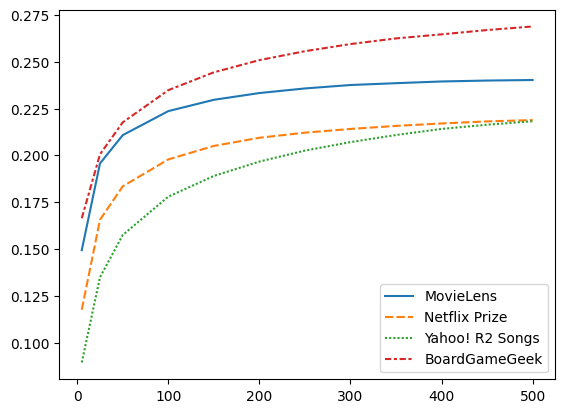

In [15]:
sns.lineplot({'MovieLens':results['ml'], 'Netflix Prize':results['np'], 'Yahoo! R2 Songs':results['yh'], 'BoardGameGeek':results['bg']})

[Text(0.5, 1.0, 'MovieLens KNN k=500 Predicted Ratings Distribution'),
 Text(0.5, 0, 'Actual Ratings'),
 Text(0, 0.5, 'Predicted Ratings')]

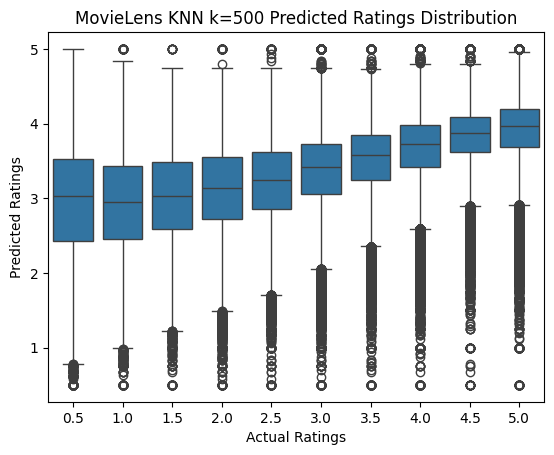

In [16]:
sns.boxplot(x=ml_common_ratings_df['rating'], y=ml_common_ratings_df['pred_rating']).set(title='MovieLens KNN k=500 Predicted Ratings Distribution', xlabel='Actual Ratings', ylabel='Predicted Ratings')

[Text(0.5, 1.0, 'Netflix Prize KNN k=500 Predicted Ratings Distribution'),
 Text(0.5, 0, 'Actual Ratings'),
 Text(0, 0.5, 'Predicted Ratings')]

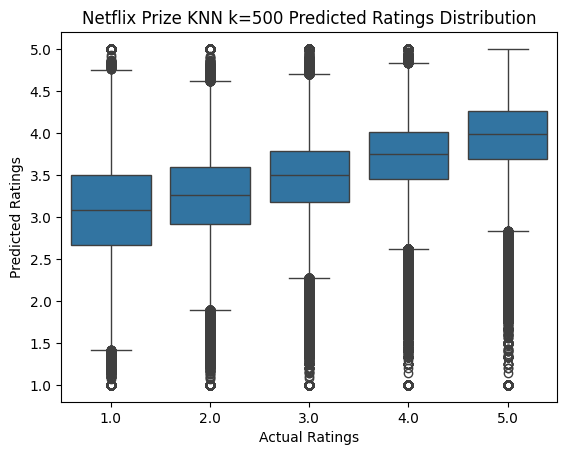

In [17]:
sns.boxplot(x=np_common_ratings_df['rating'], y=np_common_ratings_df['pred_rating']).set(title='Netflix Prize KNN k=500 Predicted Ratings Distribution', xlabel='Actual Ratings', ylabel='Predicted Ratings')

[Text(0.5, 1.0, 'Yahoo! R2 Songs KNN k=500 Predicted Ratings Distribution'),
 Text(0.5, 0, 'Actual Ratings'),
 Text(0, 0.5, 'Predicted Ratings')]

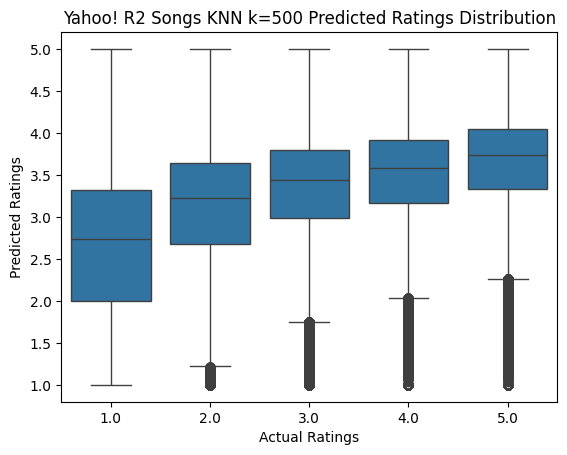

In [18]:
sns.boxplot(x=yh_common_ratings_df['rating'], y=yh_common_ratings_df['pred_rating']).set(title='Yahoo! R2 Songs KNN k=500 Predicted Ratings Distribution', xlabel='Actual Ratings', ylabel='Predicted Ratings')

[Text(0.5, 1.0, 'MovieLens k=500 Ratings Per User')]

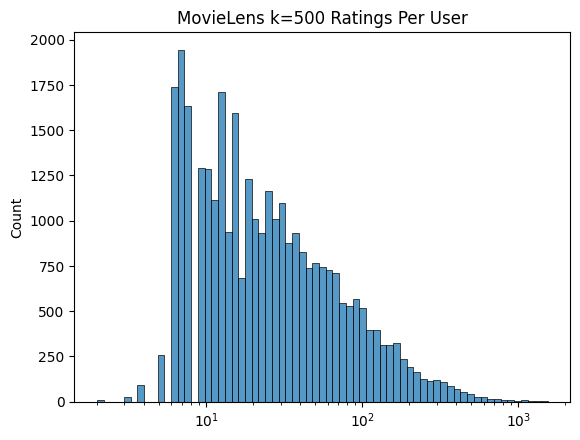

In [19]:
ml_rating_per_user = ml_common_ratings_df.group_by('user_id').agg(num_ratings=pl.col('item_id').n_unique())
sns.histplot(data=ml_rating_per_user['num_ratings'], log_scale=(True, False)).set(title="MovieLens k=500 Ratings Per User")

[Text(0.5, 1.0, 'Netflix Prize Ratings k=500 Per User')]

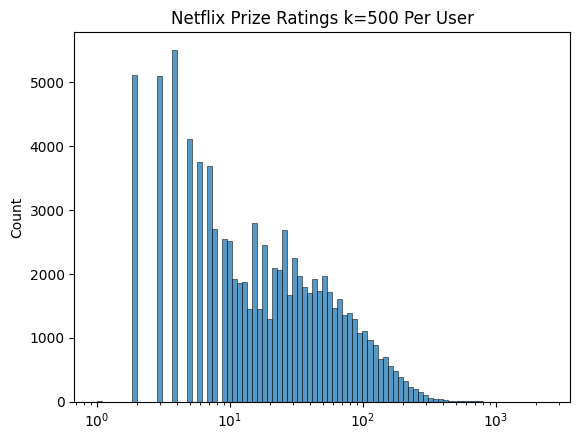

In [20]:
np_rating_per_user = np_common_ratings_df.group_by('user_id').agg(num_ratings=pl.col('item_id').n_unique())
sns.histplot(data=np_rating_per_user['num_ratings'], log_scale=(True, False)).set(title="Netflix Prize Ratings k=500 Per User")

[Text(0.5, 1.0, 'Yahoo! R2 Songs k=500 Ratings Per User')]

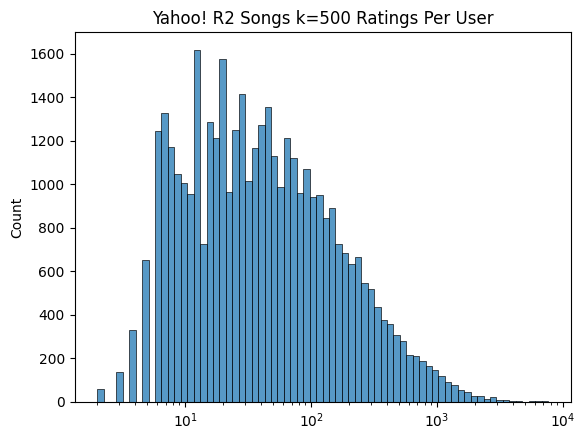

In [21]:
yh_rating_per_user = yh_common_ratings_df.group_by('user_id').agg(num_ratings=pl.col('item_id').n_unique())
sns.histplot(data=yh_rating_per_user['num_ratings'], log_scale=(True, False)).set(title="Yahoo! R2 Songs k=500 Ratings Per User")

[Text(0.5, 1.0, 'BoardGameGeek k=500 Ratings Per User')]

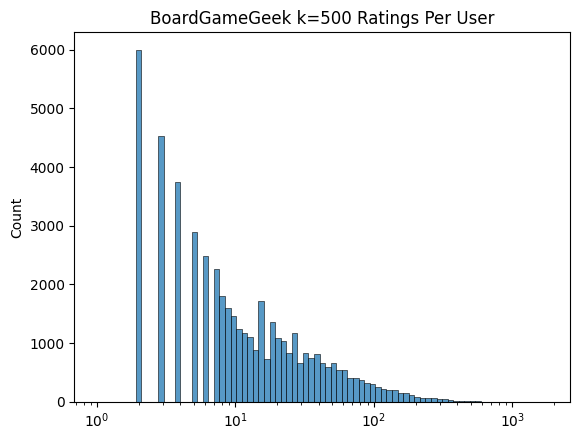

In [22]:
bg_rating_per_user = bg_common_ratings_df.group_by('user_id').agg(num_ratings=pl.col('item_id').n_unique())
sns.histplot(data=bg_rating_per_user['num_ratings'], log_scale=(True, False)).set(title="BoardGameGeek k=500 Ratings Per User")